# DSCI 552 - Homework 5
**Xinyi Wu**

## 1. Decision Trees as Interpretable Models

### 1(a) Load the Acute Inflammations Dataset

In [2]:
import pandas as pd
import numpy as np

# Load the Acute Inflammations dataset
df = pd.read_csv(
    "diagnosis.data",
    header=None,
    sep="\t",
    encoding="utf-16",
    decimal=","
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (120, 8)


,0,1,2,3,4,5,6,7
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


### 1(b) Build and Plot a Decision Tree

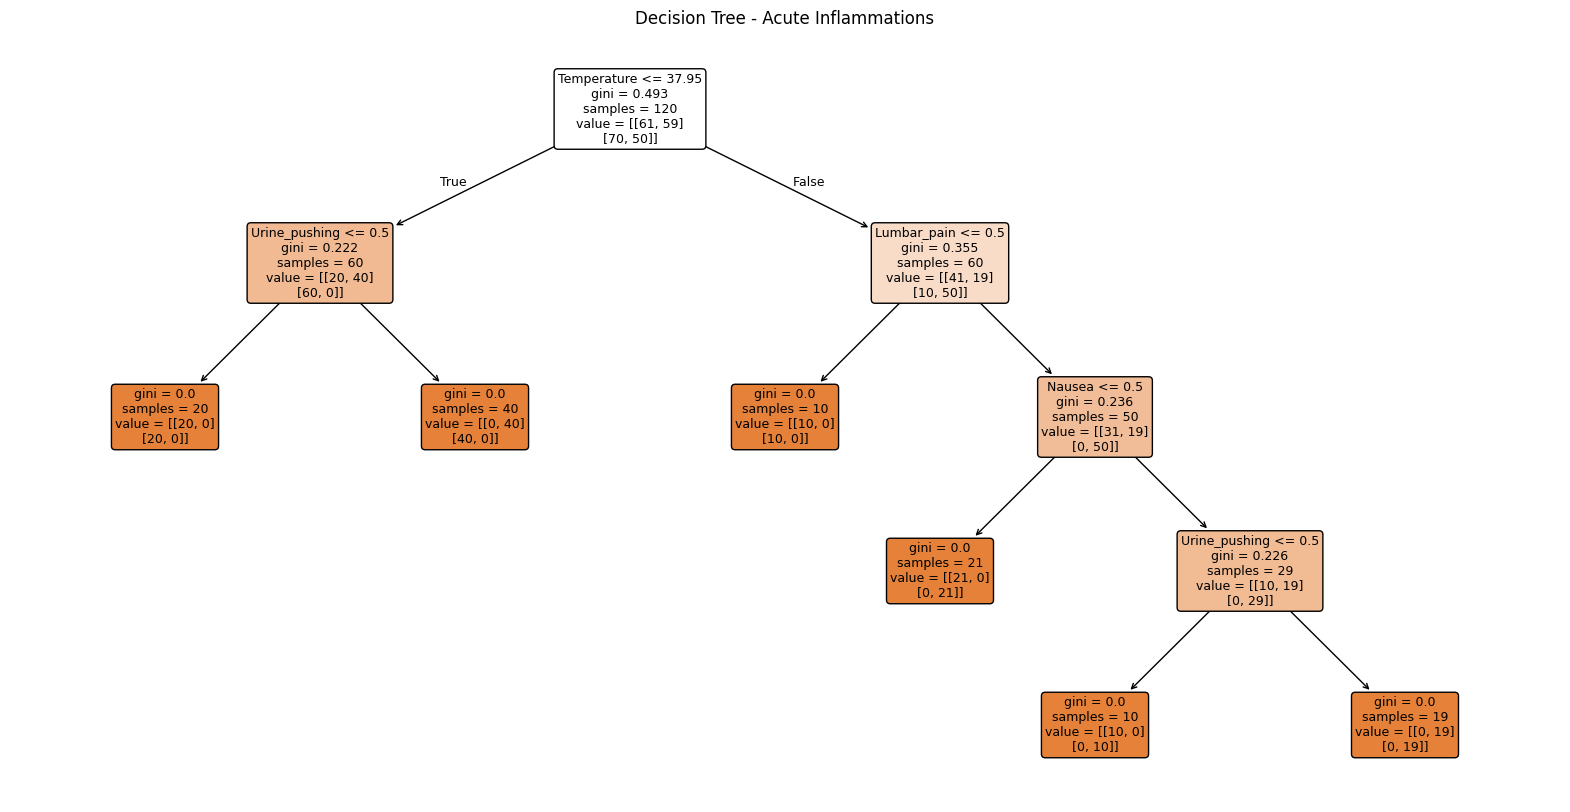

Tree depth: 4
Number of leaves: 6
Training accuracy: 1.0


In [3]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

# Assign column names
df.columns = [
    "Temperature",
    "Nausea",
    "Lumbar_pain",
    "Urine_pushing",
    "Micturition_pains",
    "Burning_urethra",
    "Inflammation",
    "Nephritis"
]

# Convert yes/no to 1/0
for col in df.columns[1:]:
    df[col] = df[col].map({"yes": 1, "no": 0})

# Separate features and labels
X = df.iloc[:, :6]
y = df.iloc[:, 6:]

# Train a multi-output decision tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X, y)

# Plot the decision tree
plt.figure(figsize=(20, 10))
plot_tree(
    dt,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Decision Tree - Acute Inflammations")
plt.show()

print("Tree depth:", dt.get_depth())
print("Number of leaves:", dt.get_n_leaves())
print("Training accuracy:", dt.score(X, y))

### 1(c) Convert Decision Rules into IF-THEN Rules

In [4]:
from sklearn.tree import _tree

def extract_if_then_rules(model, feature_names):
    tree = model.tree_
    rules = []

    def recurse(node, conditions):
        if tree.feature[node] != _tree.TREE_UNDEFINED:
            feature = feature_names[tree.feature[node]]
            threshold = tree.threshold[node]

            recurse(
                tree.children_left[node],
                conditions + [f"{feature} <= {threshold:.2f}"]
            )
            recurse(
                tree.children_right[node],
                conditions + [f"{feature} > {threshold:.2f}"]
            )
        else:
            prediction = model.classes_
            leaf_prediction = [
                classes[np.argmax(tree.value[node][i])]
                for i, classes in enumerate(prediction)
            ]

            rules.append(
                "IF " + " AND ".join(conditions)
                + "\nTHEN Inflammation = "
                + str(leaf_prediction[0])
                + ", Nephritis = "
                + str(leaf_prediction[1])
            )

    recurse(0, [])
    return rules

rules = extract_if_then_rules(dt, list(X.columns))

for i, rule in enumerate(rules, 1):
    print(f"Rule {i}:")
    print(rule)
    print()

Rule 1:
IF Temperature <= 37.95 AND Urine_pushing <= 0.50
THEN Inflammation = 0, Nephritis = 0

Rule 2:
IF Temperature <= 37.95 AND Urine_pushing > 0.50
THEN Inflammation = 1, Nephritis = 0

Rule 3:
IF Temperature > 37.95 AND Lumbar_pain <= 0.50
THEN Inflammation = 0, Nephritis = 0

Rule 4:
IF Temperature > 37.95 AND Lumbar_pain > 0.50 AND Nausea <= 0.50
THEN Inflammation = 0, Nephritis = 1

Rule 5:
IF Temperature > 37.95 AND Lumbar_pain > 0.50 AND Nausea > 0.50 AND Urine_pushing <= 0.50
THEN Inflammation = 0, Nephritis = 1

Rule 6:
IF Temperature > 37.95 AND Lumbar_pain > 0.50 AND Nausea > 0.50 AND Urine_pushing > 0.50
THEN Inflammation = 1, Nephritis = 1



### 1(d) Cost-Complexity Pruning

,ccp_alpha,Tree Depth,Leaves,Training Accuracy
0,0.000000,4,6,1.000000
1,0.049083,2,4,0.841667
2,0.079472,2,3,0.758333
3,0.111111,1,2,0.591667
4,0.204236,0,1,0.250000


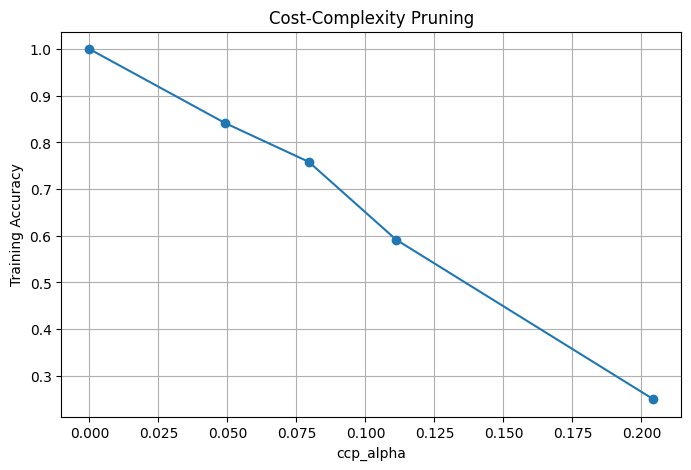

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier

# Generate the cost-complexity pruning path
path = dt.cost_complexity_pruning_path(X, y)
ccp_alphas = path.ccp_alphas

results = []

for alpha in ccp_alphas:
    model = DecisionTreeClassifier(
        random_state=42,
        ccp_alpha=alpha
    )
    model.fit(X, y)

    results.append({
        "ccp_alpha": alpha,
        "Tree Depth": model.get_depth(),
        "Leaves": model.get_n_leaves(),
        "Training Accuracy": model.score(X, y)
    })

pruning_results = pd.DataFrame(results)
display(pruning_results)

# Plot accuracy versus pruning strength
plt.figure(figsize=(8, 5))
plt.plot(
    pruning_results["ccp_alpha"],
    pruning_results["Training Accuracy"],
    marker="o"
)
plt.xlabel("ccp_alpha")
plt.ylabel("Training Accuracy")
plt.title("Cost-Complexity Pruning")
plt.grid(True)
plt.show()

In [6]:
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier

cv_results = []

for alpha in ccp_alphas:
    model = DecisionTreeClassifier(
        random_state=42,
        ccp_alpha=alpha
    )

    scores = cross_val_score(
        model,
        X,
        y,
        cv=5,
        scoring="accuracy"
    )

    cv_results.append({
        "ccp_alpha": alpha,
        "Mean CV Accuracy": scores.mean(),
        "CV Std": scores.std()
    })

cv_df = pd.DataFrame(cv_results)
display(cv_df)

best_alpha = cv_df.loc[
    cv_df["Mean CV Accuracy"].idxmax(),
    "ccp_alpha"
]

print("Best ccp_alpha:", best_alpha)

,ccp_alpha,Mean CV Accuracy,CV Std
0,0.000000,0.950000,0.100000
1,0.049083,0.741667,0.247768
2,0.079472,0.708333,0.260875
3,0.111111,0.566667,0.140929
4,0.204236,0.200000,0.209828


Best ccp_alpha: 0.0


1(d) Final Tree and IF-THEN Rules

**Interpretation:**

Cost-complexity pruning was evaluated using 5-fold cross-validation. The unpruned decision tree (`ccp_alpha = 0`) achieved the highest mean cross-validation accuracy of 95.00%, with a depth of 4 and 6 leaf nodes.

Increasing the pruning parameter reduced tree complexity but also substantially decreased classification accuracy. Although pruning produced smaller trees, none of the pruned models achieved comparable predictive performance.

Therefore, the original decision tree was retained as the final model. Its six IF-THEN rules provide a relatively compact and interpretable representation of the classification process.

## 2. The LASSO and Boosting for Regression

### 2(a) Load and Split the Communities and Crime Dataset

In [8]:
import pandas as pd
import numpy as np

# Load the Communities and Crime dataset
crime_df = pd.read_csv(
    "communities.data",
    header=None,
    na_values="?"
)

print("Dataset shape:", crime_df.shape)
display(crime_df.head())

# Split data according to the homework instructions
train_df = crime_df.iloc[:1495].copy()
test_df = crime_df.iloc[1495:].copy()

print("Training set shape:", train_df.shape)
print("Test set shape:", test_df.shape)

Dataset shape: (1994, 128)


,0,1,2,3,4,5,6,7,8,9,...,118,119,120,121,122,123,124,125,126,127
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


Training set shape: (1495, 128)
Test set shape: (499, 128)


### 2(b) Handle Missing Values and Remove Non-Predictive Features

In [9]:
# Non-predictive columns identified in the dataset description
non_predictive_cols = [0, 1, 2, 3, 4]

# Column 127 is the target: ViolentCrimesPerPop
target_col = 127

# Separate predictors and target
X_train = train_df.drop(
    columns=non_predictive_cols + [target_col]
)
X_test = test_df.drop(
    columns=non_predictive_cols + [target_col]
)

y_train = train_df[target_col]
y_test = test_df[target_col]

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)

print("\nMissing values in training features:",
      X_train.isna().sum().sum())

print("Missing values in test features:",
      X_test.isna().sum().sum())

print("\nColumns with missing values:")
display(X_train.isna().sum()[X_train.isna().sum() > 0])

Training features: (1495, 122)
Test features: (499, 122)

Missing values in training features: 27633
Missing values in test features: 9218

Columns with missing values:


,0
30,1
101,1256
102,1256
103,1256
104,1256
105,1256
106,1256
107,1256
108,1256
109,1256


2(b) Missing Value Imputation

In [10]:
from sklearn.impute import SimpleImputer

# Use the median of the training data to fill missing values
imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Training shape:", X_train_imputed.shape)
print("Test shape:", X_test_imputed.shape)

print("Missing values in training:",
      X_train_imputed.isna().sum().sum())

print("Missing values in test:",
      X_test_imputed.isna().sum().sum())

Training shape: (1495, 122)
Test shape: (499, 122)
Missing values in training: 0
Missing values in test: 0


### 2(c) Correlation Matrix

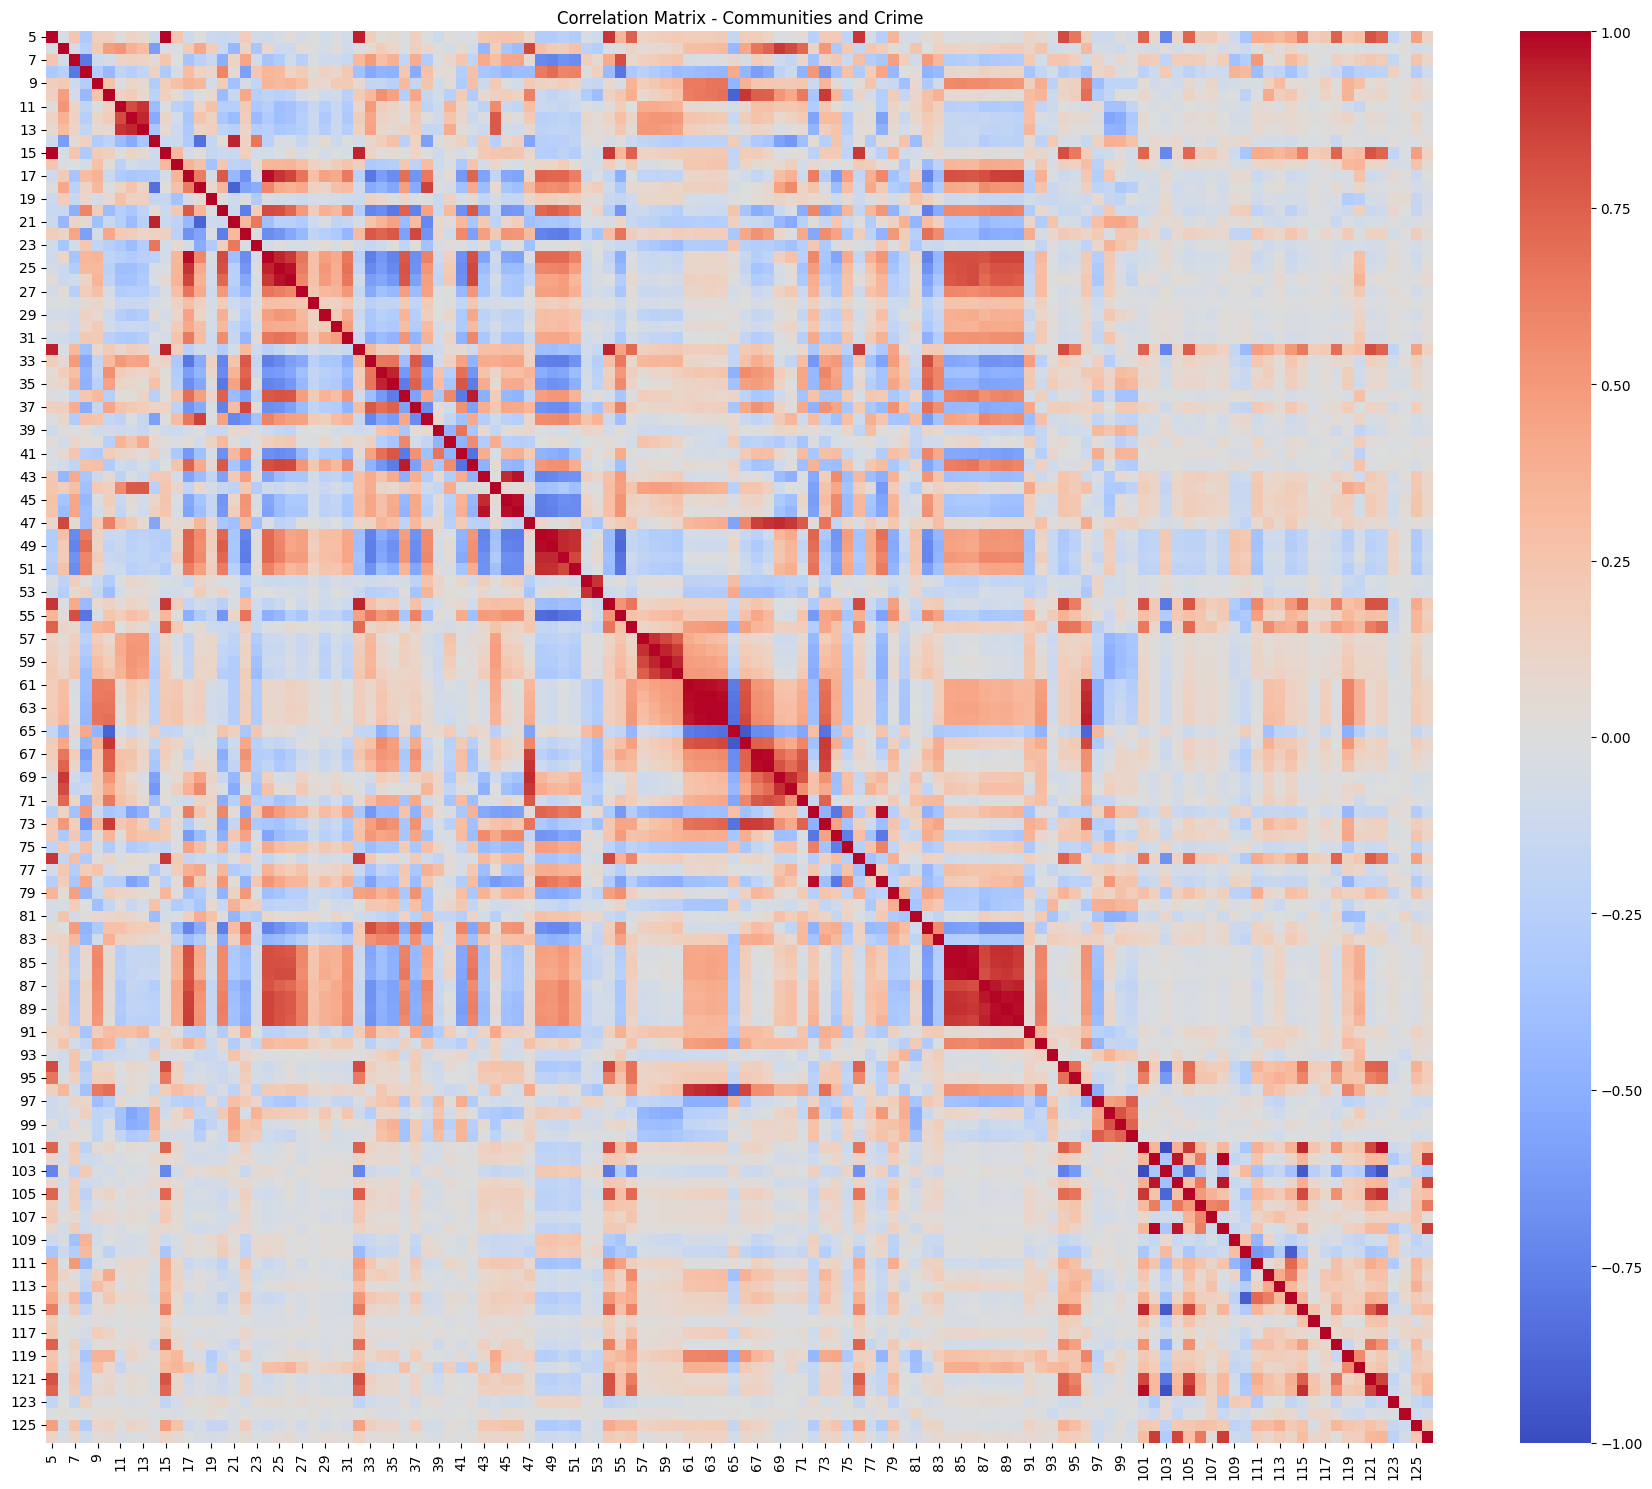

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Correlation matrix of the imputed training features
corr_matrix = X_train_imputed.corr()

plt.figure(figsize=(18, 15))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix - Communities and Crime")
plt.tight_layout()
plt.show()

**Interpretation:**

The correlation matrix shows that several features have strong positive or negative linear correlations, indicating potential multicollinearity among the predictors.

The diagonal values are equal to 1 because each feature is perfectly correlated with itself.

These correlations suggest that regularized regression methods, such as Ridge and LASSO, may be useful for handling correlated predictors and improving model stability.

### 2(d) Calculate the Coefficient of Variation

In [12]:
# Calculate coefficient of variation for each feature
feature_means = X_train_imputed.mean()
feature_stds = X_train_imputed.std(ddof=1)

cv_values = feature_stds / feature_means.replace(0, np.nan)

cv_df_features = pd.DataFrame({
    "Mean": feature_means,
    "Standard Deviation": feature_stds,
    "CV": cv_values
})

display(cv_df_features.sort_values("CV", ascending=False))

,Mean,Standard Deviation,CV
113,0.016254,0.089838,5.527059
95,0.022983,0.098665,4.292923
94,0.029599,0.102736,3.470952
54,0.037204,0.113806,3.058964
56,0.030595,0.089541,2.926635
...,...,...,...
116,0.567130,0.079977,0.141021
109,0.722375,0.093657,0.129652
110,0.762856,0.090572,0.118727
123,0.752495,0.084304,0.112032


### 2(e) Select Features with Highest CV and Create Scatter Plots and Box Plots

In [13]:
# Select the top floor(sqrt(128)) features by CV
n_features = int(np.floor(np.sqrt(128)))

top_features = (
    cv_df_features["CV"]
    .dropna()
    .nlargest(n_features)
    .index
    .tolist()
)

print("Number of selected features:", n_features)
print("Selected feature columns:", top_features)

display(cv_df_features.loc[top_features])

Number of selected features: 11
Selected feature columns: [113, 95, 94, 54, 56, 125, 32, 101, 5, 15, 76]


,Mean,Standard Deviation,CV
113,0.016254,0.089838,5.527059
95,0.022983,0.098665,4.292923
94,0.029599,0.102736,3.470952
54,0.037204,0.113806,3.058964
56,0.030595,0.089541,2.926635
125,0.093304,0.238201,2.552946
32,0.056849,0.133167,2.342443
101,0.028749,0.064629,2.248042
5,0.058167,0.130359,2.241105
15,0.064649,0.131784,2.038461


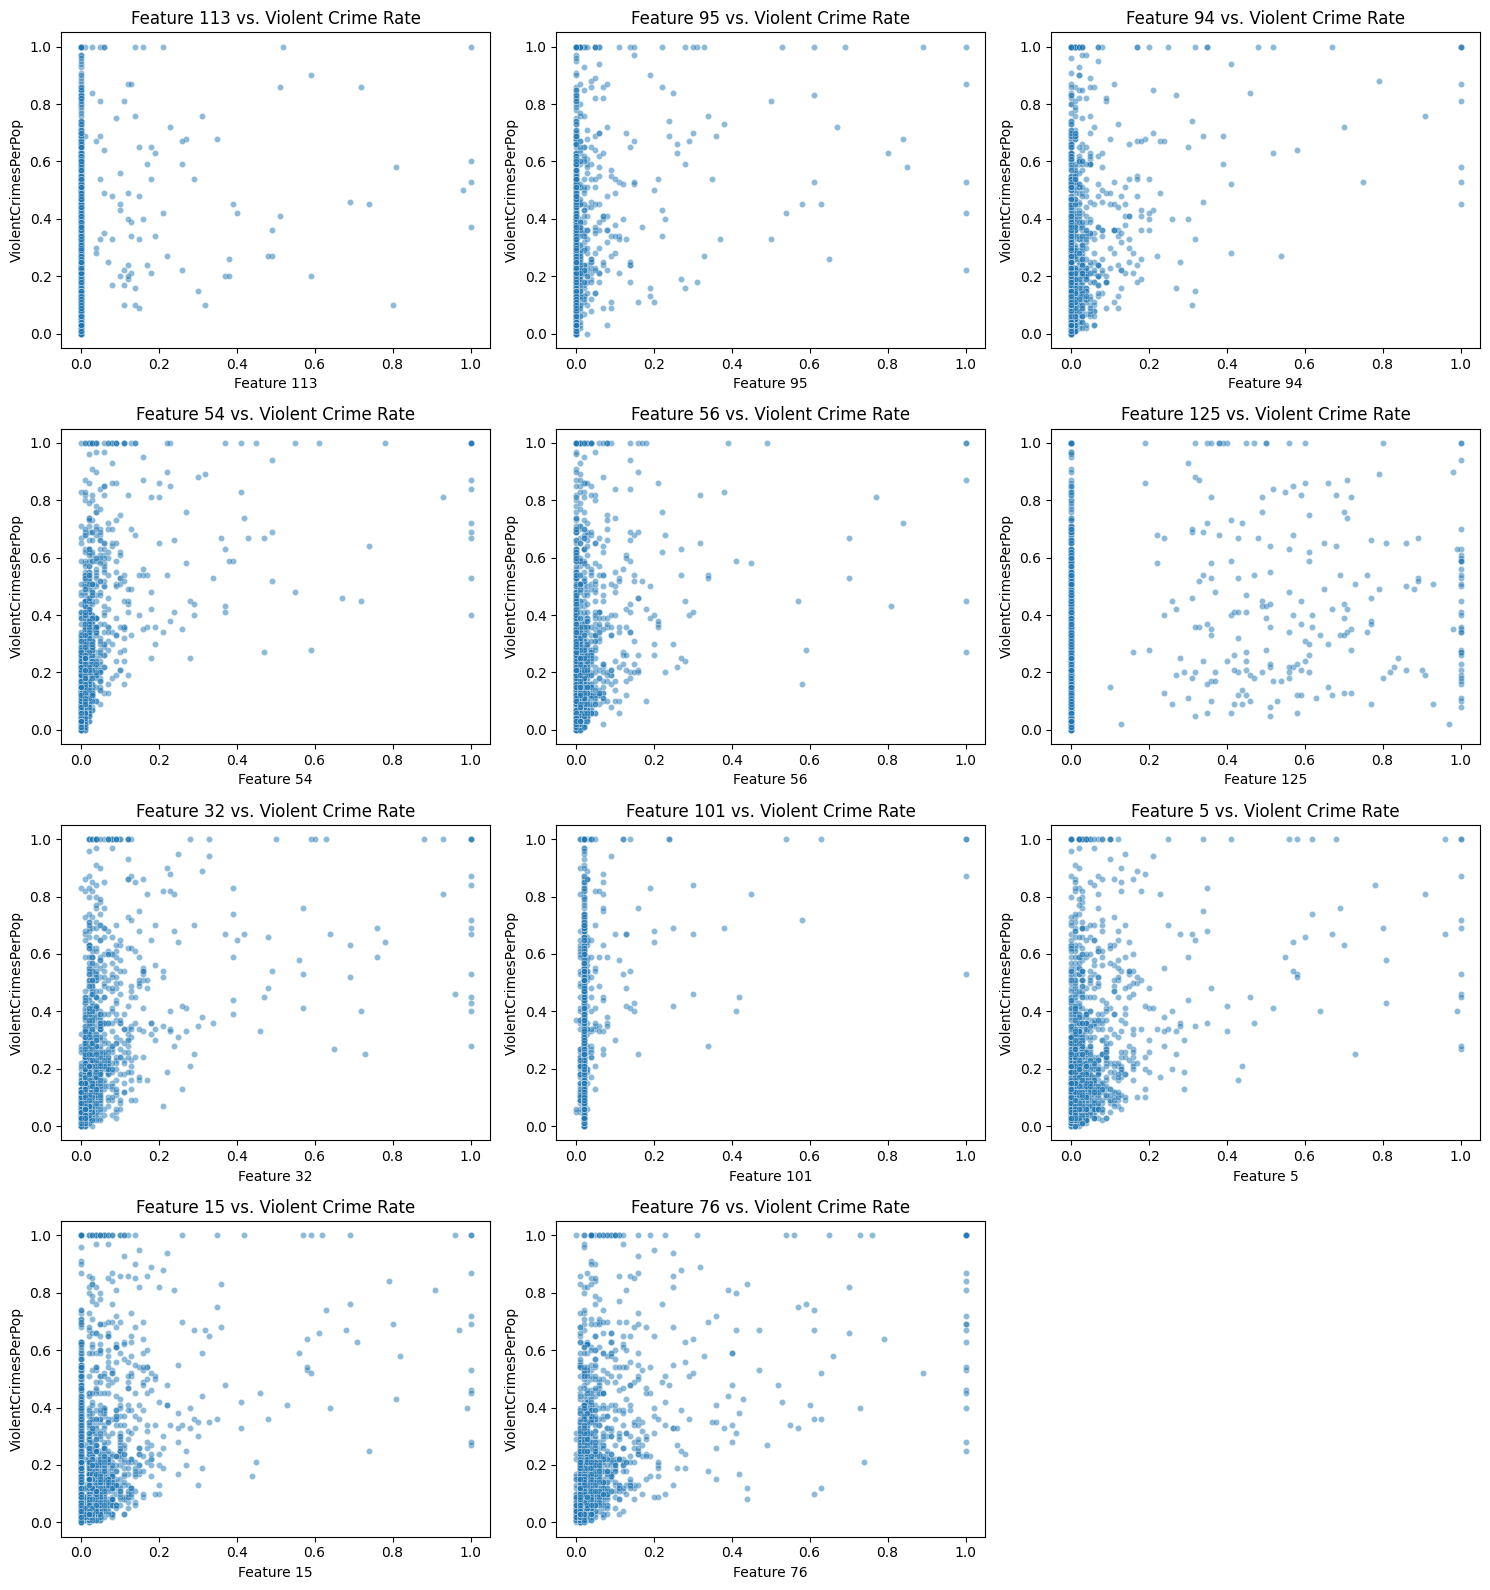

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Scatter plots: selected features vs. target
fig, axes = plt.subplots(4, 3, figsize=(15, 16))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    sns.scatterplot(
        x=X_train_imputed[feature],
        y=y_train,
        ax=axes[i],
        alpha=0.5,
        s=20
    )

    axes[i].set_title(f"Feature {feature} vs. Violent Crime Rate")
    axes[i].set_xlabel(f"Feature {feature}")
    axes[i].set_ylabel("ViolentCrimesPerPop")

# Hide unused subplot
for j in range(len(top_features), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

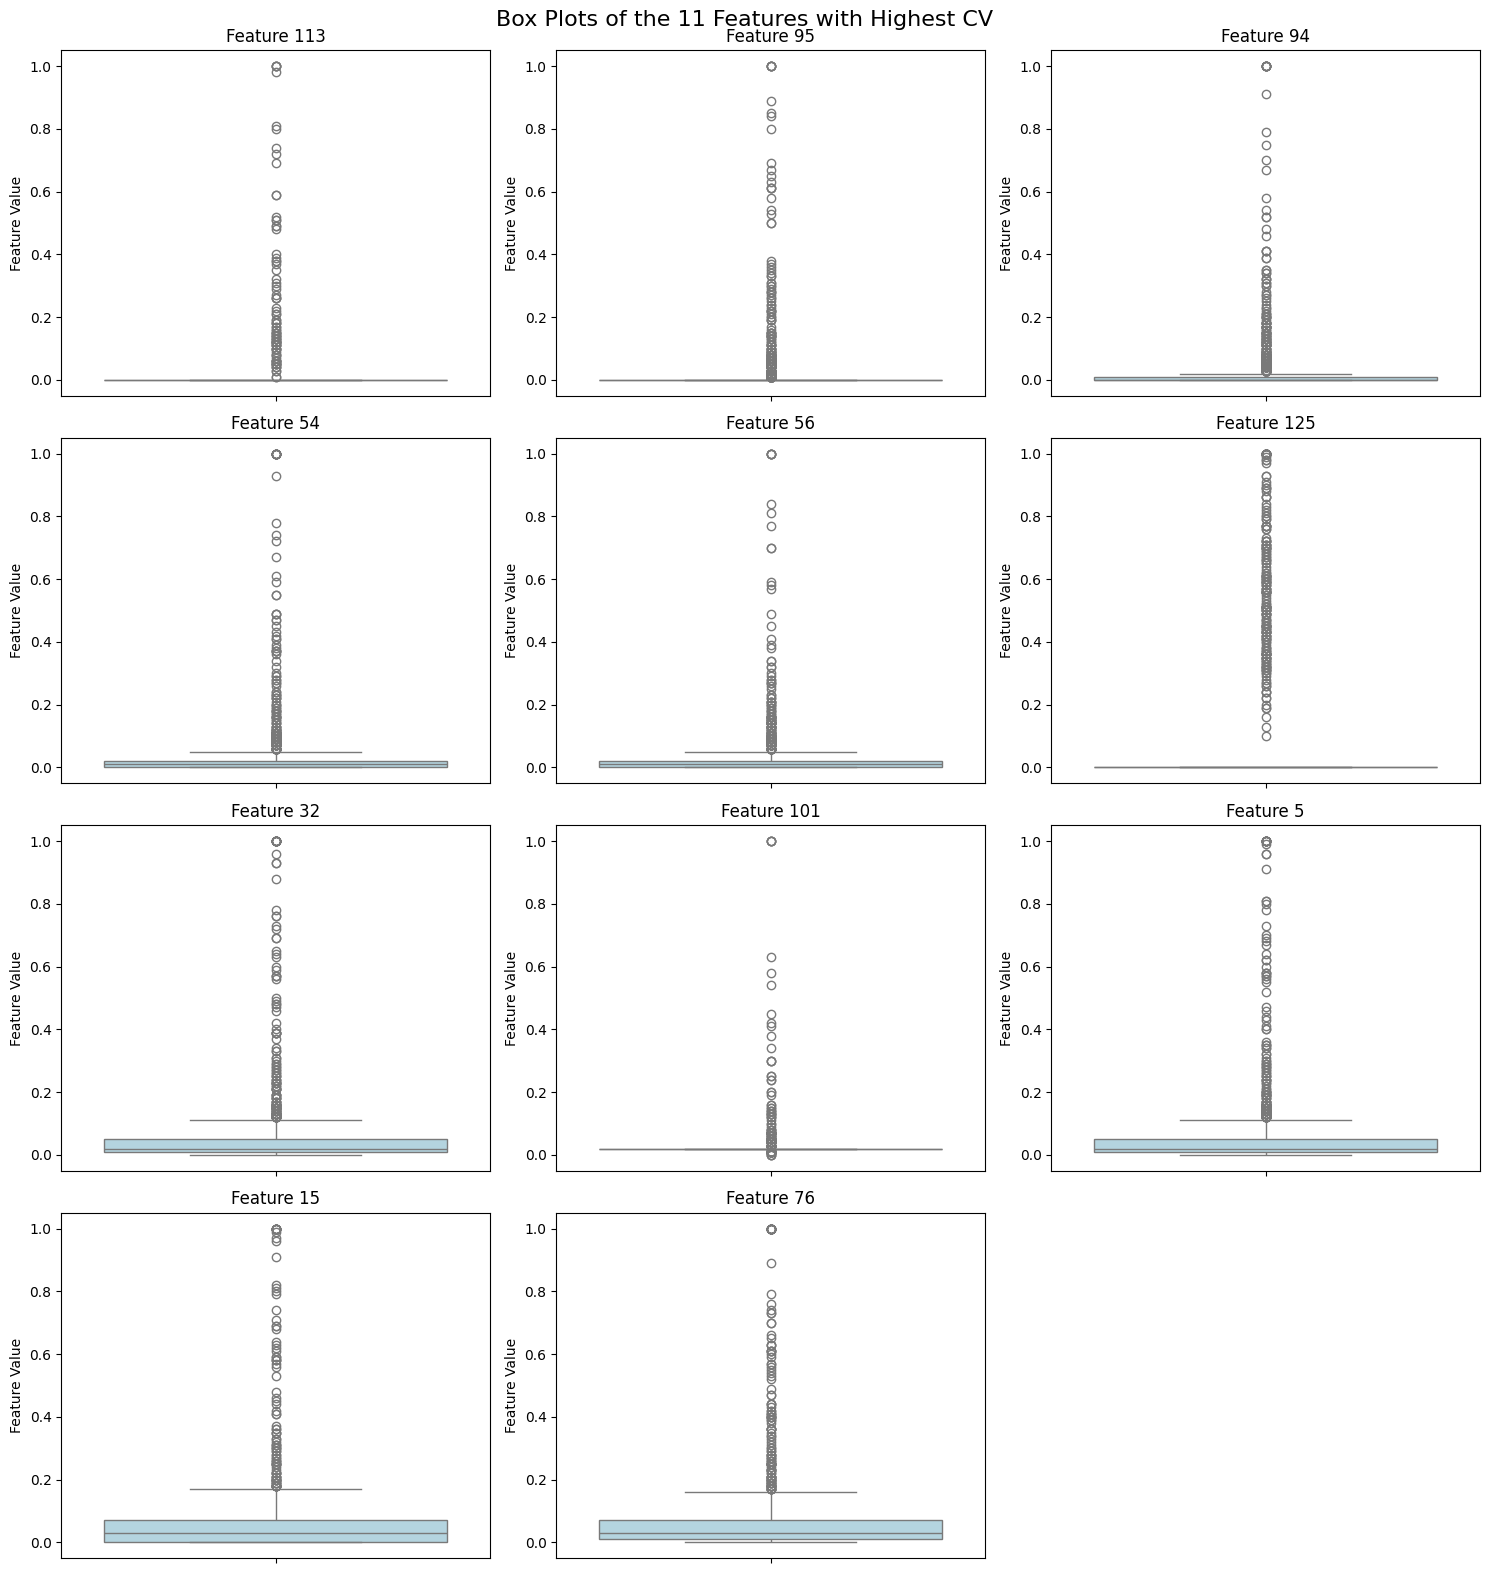

In [15]:
# Box plots for the 11 selected features
fig, axes = plt.subplots(4, 3, figsize=(15, 16))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    sns.boxplot(
        y=X_train_imputed[feature],
        ax=axes[i],
        color="lightblue"
    )

    axes[i].set_title(f"Feature {feature}")
    axes[i].set_ylabel("Feature Value")

# Hide unused subplot
for j in range(len(top_features), len(axes)):
    axes[j].axis("off")

plt.suptitle(
    "Box Plots of the 11 Features with Highest CV",
    fontsize=16
)

plt.tight_layout()
plt.show()

**Interpretation:**

The 11 features with the highest coefficients of variation exhibit substantial relative variability. The box plots show that most observations are concentrated near zero, with narrow interquartile ranges and numerous high-value outliers. This suggests that many of these features have right-skewed distributions.

The scatter plots do not reveal consistently strong linear relationships between the selected predictors and the violent crime rate.

Therefore, we cannot determine the statistical significance or predictive importance of these features based solely on scatter plots. Further statistical analysis and regression modeling are needed to evaluate their relationships with the response variable.

### 2(f) Least Squares Linear Regression

In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Fit ordinary least squares regression
ols_model = LinearRegression()
ols_model.fit(X_train_imputed, y_train)

# Predict on the test set
y_pred_ols = ols_model.predict(X_test_imputed)

# Calculate test error
ols_test_mse = mean_squared_error(y_test, y_pred_ols)

print("OLS Test MSE:", ols_test_mse)
print("OLS Test RMSE:", np.sqrt(ols_test_mse))

OLS Test MSE: 0.017966215426067328
OLS Test RMSE: 0.1340381118416226


### 2(g) Ridge Regression with Cross-Validation

In [17]:
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error
import numpy as np

# Candidate regularization parameters
alphas = np.logspace(-4, 4, 100)

# Select alpha using 5-fold cross-validation
ridge_model = RidgeCV(
    alphas=alphas,
    cv=5,
    scoring="neg_mean_squared_error"
)

# Fit the Ridge model
ridge_model.fit(X_train_imputed, y_train)

# Predict on the test set
y_pred_ridge = ridge_model.predict(X_test_imputed)

# Calculate test error
ridge_test_mse = mean_squared_error(y_test, y_pred_ridge)

print("Best Ridge alpha:", ridge_model.alpha_)
print("Ridge Test MSE:", ridge_test_mse)
print("Ridge Test RMSE:", np.sqrt(ridge_test_mse))

Best Ridge alpha: 2.310129700083163
Ridge Test MSE: 0.01751624930256489
Ridge Test RMSE: 0.13234896789384076


### 2(h) LASSO Regression with and without Standardization

In [18]:
from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd

# LASSO without additional standardization
lasso_model = LassoCV(
    cv=5,
    random_state=42,
    max_iter=100000
)

lasso_model.fit(X_train_imputed, y_train)

# Test predictions
y_pred_lasso = lasso_model.predict(X_test_imputed)
lasso_test_mse = mean_squared_error(y_test, y_pred_lasso)

# Selected features (nonzero coefficients)
selected_features = X_train_imputed.columns[
    np.abs(lasso_model.coef_) > 1e-6
].tolist()

print("Best LASSO alpha:", lasso_model.alpha_)
print("LASSO Test MSE:", lasso_test_mse)
print("LASSO Test RMSE:", np.sqrt(lasso_test_mse))
print("Number of selected features:", len(selected_features))
print("Selected features:", selected_features)

Best LASSO alpha: 0.00012454087437758504
LASSO Test MSE: 0.017617760569778627
LASSO Test RMSE: 0.13273191240157217
Number of selected features: 74
Selected features: [7, 9, 11, 12, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 41, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 57, 60, 64, 66, 68, 69, 72, 73, 74, 75, 76, 77, 79, 80, 81, 82, 83, 84, 87, 90, 91, 92, 93, 94, 95, 96, 97, 99, 104, 107, 109, 111, 112, 113, 116, 117, 118, 119, 120, 121, 123, 124]


2(h) — LASSO Without Standardization

In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LassoCV

# Standardize predictors and fit LASSO
lasso_scaled_model = make_pipeline(
    StandardScaler(),
    LassoCV(
        cv=5,
        random_state=42,
        max_iter=100000
    )
)

lasso_scaled_model.fit(X_train_imputed, y_train)

# Predict and calculate test error
y_pred_lasso_scaled = lasso_scaled_model.predict(X_test_imputed)

lasso_scaled_test_mse = mean_squared_error(
    y_test, y_pred_lasso_scaled
)

# Extract fitted LASSO model
lasso_scaled = lasso_scaled_model.named_steps["lassocv"]

selected_features_scaled = X_train_imputed.columns[
    np.abs(lasso_scaled.coef_) > 1e-6
].tolist()

print("Best standardized LASSO alpha:", lasso_scaled.alpha_)
print("Standardized LASSO Test MSE:", lasso_scaled_test_mse)
print("Standardized LASSO Test RMSE:", np.sqrt(lasso_scaled_test_mse))
print("Number of selected features:", len(selected_features_scaled))
print("Selected features:", selected_features_scaled)

Best standardized LASSO alpha: 0.0007630833878262516
Standardized LASSO Test MSE: 0.017682000986749827
Standardized LASSO Test RMSE: 0.13297368531686948
Number of selected features: 72
Selected features: [7, 9, 11, 12, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 58, 60, 64, 66, 68, 69, 72, 73, 74, 76, 77, 79, 80, 81, 82, 83, 87, 90, 91, 92, 93, 94, 95, 96, 99, 104, 105, 107, 109, 111, 112, 113, 115, 116, 117, 118, 119, 120, 121, 123, 124]


**Interpretation:**

LASSO regression was fitted with and without feature standardization, using 5-fold cross-validation to select the regularization parameter.

Without additional standardization, LASSO achieved a test MSE of 0.017618 and selected 74 predictors. With standardization, the test MSE was 0.017682, and 72 predictors were selected.

The unstandardized model achieved slightly lower test error, while the standardized model produced a slightly sparser solution. Overall, the predictive performances of the two models were very similar.

### 2(i) Principal Component Regression (PCR)

In [20]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error

# PCR pipeline
pcr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("regression", LinearRegression())
])

# Candidate numbers of principal components
n_components = list(range(1, 123))

# Select the best number using 5-fold CV
pcr_search = GridSearchCV(
    estimator=pcr_pipeline,
    param_grid={"pca__n_components": n_components},
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

pcr_search.fit(X_train_imputed, y_train)

# Evaluate on the test set
y_pred_pcr = pcr_search.predict(X_test_imputed)
pcr_test_mse = mean_squared_error(y_test, y_pred_pcr)

print("Best number of principal components:",
      pcr_search.best_params_["pca__n_components"])

print("PCR Test MSE:", pcr_test_mse)
print("PCR Test RMSE:", np.sqrt(pcr_test_mse))

Best number of principal components: 95
PCR Test MSE: 0.018296345367709785
PCR Test RMSE: 0.1352639840005823


**Interpretation:**

Principal Component Regression (PCR) was performed using standardized predictors. Five-fold cross-validation selected 95 principal components, resulting in a test MSE of 0.018296.

Although PCR reduces the dimensionality of the original feature space, it did not improve predictive performance compared with OLS, Ridge, or LASSO in this experiment. This may be because PCA selects components based on predictor variance rather than their relationship with the response variable.

### 2(j) XGBoost Regression

In [21]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error
import numpy as np

# XGBoost model
xgb_model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=1
)

# Candidate hyperparameters
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [2, 3, 4],
    "learning_rate": [0.05, 0.1],
    "reg_alpha": [0.01, 0.1, 1, 10]
}

# Five-fold cross-validation
xgb_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

xgb_search.fit(X_train_imputed, y_train)

# Test predictions
y_pred_xgb = xgb_search.predict(X_test_imputed)
xgb_test_mse = mean_squared_error(y_test, y_pred_xgb)

print("Best XGBoost parameters:", xgb_search.best_params_)
print("XGBoost Test MSE:", xgb_test_mse)
print("XGBoost Test RMSE:", np.sqrt(xgb_test_mse))

Best XGBoost parameters: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 200, 'reg_alpha': 0.1}
XGBoost Test MSE: 0.01638451678116944
XGBoost Test RMSE: 0.12800201866052519


**Model Comparison and Conclusion**

Six regression models were evaluated using the same training and test split. Cross-validation was used to select the tuning parameters for Ridge, LASSO, PCR, and XGBoost.

XGBoost achieved the lowest test MSE (0.016385), followed by Ridge regression (0.017516). Both LASSO models produced similar test errors, while PCR had the highest test MSE (0.018296).

These results suggest that XGBoost provides the best predictive performance among the evaluated models on this test set. Its ability to model nonlinear relationships and interactions may help explain its improvement over linear regression methods.